SmartFleet: day-ahead taxi demand models vs naive benchmarks

**Task.** Predict yellow-taxi `pickups` for each of 49 busy NYC zones (47 Manhattan + JFK + LaGuardia) for each hour,
**24 hours in advance**. One row = one zone × one hour.

**Question this notebook answers.** How much accuracy does each model gain (or lose) over the naive rules a
dispatcher could use today: *same hour yesterday*, *same hour last week*, and *average of the same hour over the last
four weeks*?

**Plan**
1. Load the table and check it against `dataset_summary.pdf`.
2. Define time-ordered CV: six monthly folds (Mar–Aug 2025), each trained on *all* earlier dev data.
3. Benchmarks: three naive rules, the per-fold historical average, and a shallow regression tree.
4. Feature set: **every model gets the same inputs**, all planned features in `dataset_summary.pdf` (location,
   demand lags, trip context, calendar, weather, holidays, NWS alerts) plus `hist_avg`; the two "test in CV" columns
   are checked once and the decision applies to all models.
5. Tune and cross-validate seven trained models: single tree, OLS, Ridge with zone × time interactions,
   Poisson GLM (log link), random forest, histogram gradient boosting, and a feedforward neural network (four
   architectures).
6. Refit on all of dev and score **once** on the held-out test year (Sep 2025 – Aug 2026).
7. The comparison table: loss/gain of each model vs each naive benchmark.
8. Where the best model wins and loses (airports vs Manhattan, hour of day, holidays), and what drives it.
9. Illustrative business impact.

**Metrics** (all on the same rows for every method):
- **MAE**: mean absolute error, in pickups per zone-hour.
- **WAPE**: total absolute error / total actual pickups (%). On a fixed set of rows it ranks methods exactly like MAE,
  but reads as "percent of demand mis-forecast".
- **Bias**: (total predicted − total actual) / total actual (%). Positive = over-forecasting (idle cabs),
  negative = under-forecasting (missed rides).

Set the environment variable `FAST=1` before launching Jupyter for a quick smoke-test run on a subsample.

In [1]:
import os
import time
import hashlib
import os
import warnings

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # deterministic GPU matmuls; set before torch loads
from pathlib import Path

import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, PoissonRegressor, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=UserWarning)  # OneHotEncoder unknown-category notices
warnings.filterwarnings("ignore", category=ConvergenceWarning)  # MLP epoch cap is deliberate
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

FAST = os.environ.get("FAST", "0") == "1"
RETRAIN = os.environ.get("RETRAIN", "0") == "1"  # ignore saved models/predictions and retrain from scratch
SEED = 0
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
CACHE_DIR = OUT / "cache"   # saved CV predictions, fitted models, test predictions (not committed)
CACHE_DIR.mkdir(exist_ok=True)
T0 = time.time()
print(f"FAST mode: {FAST}   project root: {ROOT}   neural-network device: "
      f"{torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU (no CUDA GPU found)'}")

# Chart style: light surface, recessive grid/axes, text in ink tokens, one accent hue.
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, BASE_GRAY = "#2a78d6", "#eb6834", "#a3a29c"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK2, "font.size": 10,
    "figure.dpi": 110, "axes.axisbelow": True,
})

FAST mode: False   project root: /home/leeanddrew/harvard/ai-edge/ai-edge-nyc-taxi-demand   neural-network device: NVIDIA GeForce RTX 5060 Ti


## 1. Load and check the table

In [2]:
path = next(p for p in [DATA / "model_table.csv.gz", DATA / "model_table.csv"] if p.exists())
df = pd.read_csv(path, parse_dates=["ts_hour"])
df = df.sort_values(["ts_hour", "zone_id"]).reset_index(drop=True)

ID_COLS = ["zone_id", "zone_name", "borough", "ts_hour", "split"]
TARGET = "pickups"
LOC = ["zone_code", "borough_code"]
LAGS = ["lag_h", "lag_48h", "roll_24h", "roll_7d", "lag_168h", "lag_336h", "same_hour_4wk"]
TRIP = ["duration_lag_h", "fare_lag_h"]
CAL = ["hr", "dow", "month", "is_weekend"]
HOL = ["is_holiday", "is_holiday_season", "days_to_holiday", "days_since_holiday"]
ALERTS = ["alert_winter", "alert_heat", "alert_cold", "alert_wind", "alert_flood"]
WEATHER = ["temp_c", "feels_like_c", "precip_mm", "snow_depth_m", "wind_kmh", "cloud_cover_pct",
           "is_precip", "likely_snow"]
EXTRA = ["post_cbd_pricing", "is_minor_holiday"]  # "test in CV" per the dataset summary

ALL_FEATURES = LOC + LAGS + TRIP + CAL + WEATHER + HOL + ALERTS + EXTRA
assert set(ALL_FEATURES) == set(df.columns) - set(ID_COLS) - {TARGET}, "feature groups out of sync with file"

summary = pd.Series({
    "rows": len(df),
    "zones": df.zone_id.nunique(),
    "first hour": df.ts_hour.min(),
    "last hour": df.ts_hour.max(),
    "dev rows": (df.split == "dev").sum(),
    "test rows": (df.split == "test").sum(),
    "features in file": len(ALL_FEATURES),
    "mean pickups / row": round(df[TARGET].mean(), 1),
    "median pickups / row": df[TARGET].median(),
    "share of zero rows (%)": round(100 * (df[TARGET] == 0).mean(), 2),
})
display(summary.to_frame("value"))
na = df.isna().sum()
display(na[na > 0].to_frame("missing values"))

,value
rows,1504741
zones,49
first hour,2023-01-29 00:00:00
last hour,2026-08-31 23:00:00
dev rows,1075501
test rows,429240
features in file,34
mean pickups / row,93.10
median pickups / row,62.00
share of zero rows (%),1.22


,missing values
duration_lag_h,18359
fare_lag_h,18359


Matches the summary sheet: 1,504,741 rows, 49 zones, dev 1,075,501 / test 429,240 rows. The only missing values are
the 24h-old trip duration and fare, which are empty when a zone had no trips in that hour.

In [3]:
zone_vol = (df[df.split == "dev"].groupby(["zone_name", "borough"])[TARGET].mean()
            .sort_values(ascending=False).rename("mean pickups/h").reset_index())
print("Busiest and quietest modeled zones (dev period):")
display(pd.concat([zone_vol.head(5), zone_vol.tail(5)]))

Busiest and quietest modeled zones (dev period):


,zone_name,borough,mean pickups/h
0,JFK Airport,Queens,228.87
1,Midtown Center,Manhattan,218.37
2,Upper East Side South,Manhattan,217.03
3,Upper East Side North,Manhattan,193.63
4,Midtown East,Manhattan,161.69
44,World Trade Center,Manhattan,25.12
45,Hudson Sq,Manhattan,24.24
46,Morningside Heights,Manhattan,23.82
47,Central Harlem,Manhattan,15.17
48,East Harlem North,Manhattan,13.57


Demand per zone ranges from a few pickups an hour to ~200 (JFK). That 20×+ spread matters for model choice: errors
grow with volume, and a count model with a log link (the Poisson GLM) treats effects as multiplicative, which fits
that structure naturally.

## 2. Validation design

- **Folds**: expanding window by calendar month. Fold *k* validates on one month of Mar–Aug 2025 and trains on every
  dev row before that month. Folds are cut on `ts_hour`, so all zones for an hour stay together.
- **No look-ahead**: every demand feature is already ≥ 24 h old, so no gap is needed between train and validation.
- **`hist_avg`** (mean pickups per zone × weekday × hour) is computed **inside each fold from that fold's training rows
  only**, then attached to train and validation rows. It is used both as a benchmark and as a model feature.
- **Missing trip context** is filled with the training median and flagged with `trip_missing`.
- The **test year** is not touched until section 6.

In [4]:
dev = df[df.split == "dev"].reset_index(drop=True)
test = df[df.split == "test"].reset_index(drop=True)

VAL_MONTHS = pd.period_range("2025-03", "2025-08", freq="M")
if FAST:
    VAL_MONTHS = VAL_MONTHS[-2:]
FOLDS = []
for m in VAL_MONTHS:
    start, end = m.start_time, (m + 1).start_time
    tr = np.flatnonzero(dev.ts_hour < start)
    va = np.flatnonzero((dev.ts_hour >= start) & (dev.ts_hour < end))
    FOLDS.append((str(m), tr, va))

display(pd.DataFrame([(m, len(tr), len(va), dev.ts_hour[tr].min().date(), dev.ts_hour[tr].max().date())
                      for m, tr, va in FOLDS],
                     columns=["validation month", "train rows", "validation rows", "train from", "train to"]))

,validation month,train rows,validation rows,train from,train to
0,2025-03,859117,36456,2023-01-29,2025-02-28
1,2025-04,895573,35280,2023-01-29,2025-03-31
2,2025-05,930853,36456,2023-01-29,2025-04-30
3,2025-06,967309,35280,2023-01-29,2025-05-31
4,2025-07,1002589,36456,2023-01-29,2025-06-30
5,2025-08,1039045,36456,2023-01-29,2025-07-31


In [5]:
def add_fold_features(train, *others):
    """Attach features that must be learned from training rows only (hist_avg, trip-context fill values)."""
    hist = train.groupby(["zone_id", "dow", "hr"])[TARGET].mean().rename("hist_avg")
    fill = train[TRIP].median()
    out = []
    for frame in (train, *others):
        g = frame.join(hist, on=["zone_id", "dow", "hr"])
        g["hist_avg"] = g["hist_avg"].fillna(g["same_hour_4wk"])  # safety net; every cell is seen in practice
        g["trip_missing"] = g["duration_lag_h"].isna().astype(np.int8)
        g[TRIP] = g[TRIP].fillna(fill)
        g["zone_hr"] = g.zone_code * 24 + g.hr    # interaction keys for the Ridge model
        g["zone_dow"] = g.zone_code * 7 + g.dow
        out.append(g)
    return out


def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = p - y
    return {"MAE": np.abs(e).mean(), "WAPE %": 100 * np.abs(e).sum() / y.sum(),
            "Bias %": 100 * e.sum() / y.sum(), "rows": len(y)}

## 3. Models

Every trained method sees **exactly the same input columns** (section 4); they differ only in how they use them.

| Method | Type | How it is set up here |
|---|---|---|
| Previous-day naive | rule | `lag_h` (same zone and hour, 24 h earlier) |
| Previous-week naive | rule | `lag_168h` |
| Four-week average | rule | `same_hour_4wk` (mean of the same hour over the last 4 weeks) — **main baseline** |
| Historical average | rule | `hist_avg`, zone × weekday × hour mean over all training rows |
| Single regression tree | trained benchmark | shallow tree (depth tuned in 4–8) on the same feature set as every model |
| Linear regression (OLS) | model | full feature set; numeric columns standardized, one-hot zone, hour, weekday, month |
| Ridge + interactions | model | OLS inputs **plus** one-hot zone × hour and zone × weekday (≈1,500 columns), L2 penalty tuned |
| Poisson GLM | model | full feature set, Poisson deviance, **log link**: demand lags enter as **log**-lags; L2 tuned |
| Random forest | model | 150 trees, each on a 20% row sample, min leaf 10 |
| Gradient boosting (HGB) | model | `HistGradientBoostingRegressor`, zone as native categorical, loss and size tuned |
| Neural network (MLP) | model | PyTorch feedforward ReLU network (GPU); inputs as for the GLM; loss (Poisson or √-squared-error) and architecture tuned over (64), (256), (128, 64), (256, 128, 64) |

Why the Poisson GLM uses log-lags: with a log link, `log μ = β·log(same_hour_4wk) + …` means
`μ ∝ same_hour_4wk^β`, i.e. "scale last month's level up or down by calendar, holiday and alert multipliers".
Coefficients read directly as **rate ratios**. Linear-model predictions are clipped at 0 (the GLM is positive by construction).

**Neural network design.** A feedforward ReLU network written in **PyTorch** (`TorchMLPRegressor` below), trained on
the GPU when one is available (CPU otherwise; same results, slower). It sees the same columns as every other model,
encoded like the GLM: one-hot zone/hour/weekday/month, log1p demand lags, everything standardized. Two loss functions
are compared: **Poisson deviance with a log link** (the network outputs log-rate, like the GLM) and **squared error on
√pickups** (a variance-stabilizing transform for counts). Training: Adam (learning rate 1e-3, L2 1e-4), batch 2,048,
up to 100 epochs, early stopping when the loss on the **most recent 10% of training rows** has not improved for 5
epochs (best weights restored). Seeds and cuBLAS are fixed, so runs are reproducible. Architectures run from one
hidden layer of 64 units to three layers (256 → 128 → 64).

In [6]:
LINEAR_CATS = ["zone_code", "hr", "dow", "month"]
LOG_COLS = LAGS + ["hist_avg"]


def linear_pipeline(estimator, feats, interactions=False, log_lags=False, drop_first=False, dense=False):
    cats = LINEAR_CATS + (["zone_hr", "zone_dow"] if interactions else [])
    # borough_code and is_weekend are exact functions of zone_code / dow, so they add nothing to a linear model.
    nums = [c for c in feats if c not in cats + ["borough_code", "is_weekend"]]
    steps = [("cat", OneHotEncoder(handle_unknown="ignore", drop="first" if drop_first else None,
                                   sparse_output=True), cats)]
    if log_lags:
        logs = [c for c in nums if c in LOG_COLS]
        nums = [c for c in nums if c not in logs]
        steps.append(("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), logs))
    steps.append(("num", StandardScaler(), nums))
    return make_pipeline(ColumnTransformer(steps, sparse_threshold=0.0 if dense else 1.0), estimator)



class TorchMLPRegressor(RegressorMixin, BaseEstimator):
    """Feedforward ReLU network for count targets, trained with PyTorch on GPU when available.

    loss="poisson": the network outputs log(rate) and minimizes Poisson deviance (log link, like the GLM).
    loss="sqrt_mse": squared error on sqrt(y), predictions squared back (variance-stabilizing for counts).
    Early stopping holds out the most recent `val_fraction` of the (time-ordered) training rows.
    """

    def __init__(self, hidden=(64,), loss="poisson", epochs=100, patience=5, batch_size=2048, lr=1e-3,
                 weight_decay=1e-4, val_fraction=0.1, seed=0, device="auto"):
        self.hidden, self.loss, self.epochs, self.patience = hidden, loss, epochs, patience
        self.batch_size, self.lr, self.weight_decay = batch_size, lr, weight_decay
        self.val_fraction, self.seed, self.device = val_fraction, seed, device

    def _device(self):
        return torch.device("cuda" if self.device == "auto" and torch.cuda.is_available() else
                            ("cpu" if self.device == "auto" else self.device))

    def _net(self, d_in):
        layers, d = [], d_in
        for h in self.hidden:
            layers += [torch.nn.Linear(d, h), torch.nn.ReLU()]
            d = h
        layers.append(torch.nn.Linear(d, 1))
        return torch.nn.Sequential(*layers)

    def _target(self, y):
        return y if self.loss == "poisson" else torch.sqrt(y)

    def _loss(self, out, t):
        if self.loss == "poisson":
            return torch.nn.functional.poisson_nll_loss(out, t, log_input=True, full=False)
        return torch.nn.functional.mse_loss(out, t)

    def fit(self, X, y):
        torch.manual_seed(self.seed)
        torch.use_deterministic_algorithms(True)
        dev = self._device()
        X = torch.as_tensor(np.asarray(X, dtype=np.float32), device=dev)
        y = torch.as_tensor(np.asarray(y, dtype=np.float32), device=dev)
        n_val = int(len(X) * self.val_fraction)
        Xtr, ytr, Xva, yva = X[:-n_val], y[:-n_val], X[-n_val:], y[-n_val:]
        ttr, tva = self._target(ytr), self._target(yva)

        net = self._net(X.shape[1]).to(dev)
        if self.loss == "poisson":  # start at the mean rate so early epochs are stable
            torch.nn.init.constant_(net[-1].bias, float(torch.log(ytr.mean())))
        opt = torch.optim.Adam(net.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        gen = torch.Generator(device=dev).manual_seed(self.seed)
        best, best_state, wait = np.inf, None, 0
        self.history_ = []
        for epoch in range(self.epochs):
            net.train()
            perm = torch.randperm(len(Xtr), device=dev, generator=gen)
            for i in range(0, len(Xtr), self.batch_size):
                idx = perm[i:i + self.batch_size]
                opt.zero_grad(set_to_none=True)
                self._loss(net(Xtr[idx]).squeeze(1), ttr[idx]).backward()
                opt.step()
            net.eval()
            with torch.no_grad():
                v = float(self._loss(net(Xva).squeeze(1), tva))
            self.history_.append(v)
            if v < best - 1e-6:
                best, wait = v, 0
                best_state = {k: t.detach().clone() for k, t in net.state_dict().items()}
            else:
                wait += 1
                if wait >= self.patience:
                    break
        net.load_state_dict(best_state)
        self.n_epochs_ = len(self.history_)
        self.best_epoch_ = int(np.argmin(self.history_)) + 1
        self.net_ = net.cpu()  # keep the fitted model on CPU so it pickles cleanly
        self.n_params_ = sum(p.numel() for p in net.parameters())
        return self

    def predict(self, X):
        dev = self._device()
        net = self.net_.to(dev).eval()
        out = []
        with torch.no_grad():
            Xt = np.asarray(X, dtype=np.float32)
            for i in range(0, len(Xt), 65536):
                o = net(torch.as_tensor(Xt[i:i + 65536], device=dev)).squeeze(1)
                out.append((torch.exp(o) if self.loss == "poisson" else torch.clamp(o, min=0) ** 2).cpu().numpy())
        self.net_ = net.cpu()
        return np.concatenate(out)



RF_TREES = 30 if FAST else 150
HGB_ITERS = 0.25 if FAST else 1.0  # multiplier on max_iter
MLP_EPOCHS = 5 if FAST else 100   # upper bound; early stopping usually ends far sooner

MODELS = {
    "Single tree": dict(
        make=lambda p, f: DecisionTreeRegressor(random_state=SEED, min_samples_leaf=200, **p),
        grid=[{"max_depth": d} for d in (4, 6, 8)]),
    "Linear regression (OLS)": dict(
        make=lambda p, f: linear_pipeline(LinearRegression(), f, drop_first=True),
        grid=[{}]),
    "Ridge + zone×time interactions": dict(
        make=lambda p, f: linear_pipeline(Ridge(**p), f, interactions=True),
        grid=[{"alpha": a} for a in (1.0, 100.0, 10_000.0)]),
    "Poisson GLM (log link)": dict(
        make=lambda p, f: linear_pipeline(PoissonRegressor(max_iter=1000, **p), f, log_lags=True),
        grid=[{"alpha": a} for a in (1e-6, 1e-4, 1e-2)]),
    "Random forest": dict(
        make=lambda p, f: RandomForestRegressor(n_estimators=RF_TREES, max_samples=0.2, min_samples_leaf=10,
                                                max_features=0.5, n_jobs=-1, random_state=SEED, **p),
        grid=[{}]),
    "Gradient boosting (HGB)": dict(
        make=lambda p, f: HistGradientBoostingRegressor(categorical_features=["zone_code", "borough_code"],
                                                        early_stopping=False, random_state=SEED,
                                                        **{**p, "max_iter": int(p["max_iter"] * HGB_ITERS)}),
        grid=[{"loss": "poisson", "learning_rate": 0.1, "max_leaf_nodes": 63, "max_iter": 400},
              {"loss": "poisson", "learning_rate": 0.05, "max_leaf_nodes": 127, "max_iter": 800},
              {"loss": "squared_error", "learning_rate": 0.05, "max_leaf_nodes": 127, "max_iter": 800}]),
    "Neural network (MLP)": dict(
        make=lambda p, f: linear_pipeline(TorchMLPRegressor(epochs=MLP_EPOCHS, seed=SEED, **p), f, log_lags=True,
                                          dense=True),
        grid=[{"hidden": h, "loss": l} for l in ("poisson", "sqrt_mse")
              for h in [(64,), (256,), (128, 64), (256, 128, 64)]]),
}
MODEL_NAMES = list(MODELS)
# models that take one-hot / standardized inputs through linear_pipeline
LINEAR_MODELS = {"Linear regression (OLS)", "Ridge + zone×time interactions", "Poisson GLM (log link)",
                 "Neural network (MLP)"}


def model_inputs(feats):
    return feats + ["hist_avg", "trip_missing", "zone_hr", "zone_dow"]


def fit_predict(name, params, feats, train, others):
    """Fit one model on `train`, return clipped predictions for each frame in `others`."""
    cols = feats + ["hist_avg", "trip_missing"]
    model = MODELS[name]["make"](params, cols)
    X = (lambda g: g[model_inputs(feats)]) if name in LINEAR_MODELS else (lambda g: g[cols])
    model.fit(X(train), train[TARGET])
    return model, [np.clip(model.predict(X(o)), 0, None) for o in others]


def maybe_subsample(train):
    return train.sample(150_000, random_state=SEED) if FAST else train

## 4. One feature set for every model

All models, including the single-tree benchmark, use the same inputs: **every planned (blue) feature from
`dataset_summary.pdf`**:

| Group | Columns |
|---|---|
| Location | `zone_code`, `borough_code` |
| Recent demand | `lag_h`, `lag_48h`, `roll_24h`, `roll_7d` |
| Weekly pattern | `lag_168h`, `lag_336h`, `same_hour_4wk` |
| Trip context | `duration_lag_h`, `fare_lag_h` (+ `trip_missing` flag) |
| Calendar | `hr`, `dow`, `month`, `is_weekend` |
| Weather | `temp_c`, `feels_like_c`, `precip_mm`, `snow_depth_m`, `wind_kmh`, `cloud_cover_pct`, `is_precip`, `likely_snow` |
| Holidays | `is_holiday`, `is_holiday_season`, `days_to_holiday`, `days_since_holiday` |
| Weather alerts | `alert_winter`, `alert_heat`, `alert_cold`, `alert_wind`, `alert_flood` |
| Computed per fold | `hist_avg` |

The summary flags `post_cbd_pricing` and `is_minor_holiday` as "test in CV". We test them once below with a fixed
gradient-boosting configuration and apply the decision to **all** models, so feature sets stay identical.

**Weather caveat:** weather columns hold the weather that actually *occurred* at the target hour (a perfect forecast).
Scores are therefore slightly optimistic. To size that effect, the check also runs the same set *without* weather, and
section 6 refits the best model without weather as the honest day-ahead reference.

In [7]:
PLANNED = LOC + LAGS + TRIP + CAL + WEATHER + HOL + ALERTS   # all blue features in the summary
NO_WEATHER = [c for c in PLANNED if c not in WEATHER]
FEATURE_SETS = {
    "all planned features": PLANNED,
    "all planned + CBD/minor holiday": PLANNED + EXTRA,
    "all planned − weather (honest day-ahead)": NO_WEATHER,
}
ABL_PARAMS = {"loss": "poisson", "learning_rate": 0.1, "max_leaf_nodes": 63, "max_iter": 400}

# Saved results are reused when the set-up is unchanged (fingerprint below); set RETRAIN=1 to force retraining,
# e.g. after editing model code that the fingerprint does not see.
FINGERPRINT = hashlib.md5(repr((FAST, [str(m) for m in VAL_MONTHS], FEATURE_SETS, ABL_PARAMS,
                                {n: MODELS[n]["grid"] for n in MODEL_NAMES}, RF_TREES, HGB_ITERS, MLP_EPOCHS,
                                SEED)).encode()).hexdigest()[:10]
CV_CACHE, FINAL_CACHE = CACHE_DIR / f"cv_{FINGERPRINT}.joblib", CACHE_DIR / f"final_{FINGERPRINT}.joblib"


def load_cache(path):
    if path.exists() and not RETRAIN:
        print(f"Loaded saved results from {path.relative_to(ROOT)} (set RETRAIN=1 to retrain)")
        return joblib.load(path)
    return None


cv_cache = load_cache(CV_CACHE)
if cv_cache:
    abl_pred, y_cv = cv_cache["abl_pred"], cv_cache["y_cv"]
else:
    abl_pred = {k: [] for k in FEATURE_SETS}
    y_cv = []
    t = time.time()
    for month, tr_idx, va_idx in FOLDS:
        train, val = add_fold_features(dev.iloc[tr_idx], dev.iloc[va_idx])
        train = maybe_subsample(train)
        y_cv.append(val[TARGET].to_numpy())
        for k, feats in FEATURE_SETS.items():
            _, (p,) = fit_predict("Gradient boosting (HGB)", ABL_PARAMS, feats, train, [val])
            abl_pred[k].append(p)
        print(f"  fold {month} done ({time.time() - t:.0f}s)")
y_cv_all = np.concatenate(y_cv)

ablation = pd.DataFrame({k: metrics(y_cv_all, np.concatenate(v)) for k, v in abl_pred.items()}).T
ablation["Δ MAE vs all planned"] = ablation["MAE"] - ablation.loc["all planned features", "MAE"]
display(ablation)

use_extra = ablation.loc["all planned + CBD/minor holiday", "MAE"] < ablation.loc["all planned features", "MAE"]
FEATS = PLANNED + EXTRA if use_extra else PLANNED          # the ONE feature set every model uses
FEATS_NO_WEATHER = [c for c in FEATS if c not in WEATHER]
print(f"Feature set for every model: {'all planned + CBD/minor holiday' if use_extra else 'all planned features'}"
      f" ({len(FEATS)} columns + hist_avg + trip_missing)")

Loaded saved results from results/cache/cv_f2ddec7d06.joblib (set RETRAIN=1 to retrain)


,MAE,WAPE %,Bias %,rows,Δ MAE vs all planned
all planned features,13.97,13.86,-3.88,"216,384.00",0.00
all planned + CBD/minor holiday,14.03,13.92,-0.24,"216,384.00",0.06
all planned − weather (honest day-ahead),14.01,13.90,-3.75,"216,384.00",0.04


Feature set for every model: all planned features (32 columns + hist_avg + trip_missing)


**What the check shows** (numbers from the run above)
- **CBD pricing / minor holidays do not help** (+0.06 MAE), so they are left out for every model. A likely reason:
  every validation month is after congestion pricing began (5 Jan 2025), while each fold has only 2–7 post-CBD
  training months, too few to learn a stable effect. The demand lags already carry the post-CBD level.
- **Weather is nearly free of signal here:** removing it costs only 0.04 MAE (0.3%), even though it is a *perfect*
  forecast. So the optimism from using observed weather is small. Section 6 checks this again on the test year.
- **Feature set used by every model:** all 32 planned columns (including weather and NWS alerts) + `hist_avg` +
  `trip_missing`.

## 5. Cross-validated benchmarks and models

In [8]:
if cv_cache:
    cv_pred, bench_pred, fit_seconds = cv_cache["cv_pred"], cv_cache["bench_pred"], cv_cache["fit_seconds"]
else:
    cv_pred = {(n, i): [] for n in MODEL_NAMES for i in range(len(MODELS[n]["grid"]))}
    bench_pred = {b: [] for b in ["lag_h", "lag_168h", "same_hour_4wk", "hist_avg"]}
    fit_seconds = {}
    t = time.time()
    for month, tr_idx, va_idx in FOLDS:
        train, val = add_fold_features(dev.iloc[tr_idx], dev.iloc[va_idx])
        train = maybe_subsample(train)
        for b in bench_pred:
            bench_pred[b].append(val[b].to_numpy())
        for n in MODEL_NAMES:
            for i, params in enumerate(MODELS[n]["grid"]):
                s = time.time()
                _, (p,) = fit_predict(n, params, FEATS, train, [val])
                cv_pred[(n, i)].append(p)
                fit_seconds[(n, i)] = fit_seconds.get((n, i), 0) + time.time() - s
        print(f"  fold {month} done ({time.time() - t:.0f}s)")
    joblib.dump({"abl_pred": abl_pred, "y_cv": y_cv, "cv_pred": cv_pred, "bench_pred": bench_pred,
                 "fit_seconds": fit_seconds}, CV_CACHE)
    print(f"Saved CV predictions to {CV_CACHE.relative_to(ROOT)}")

In [9]:
BENCH_LABELS = {"lag_h": "Previous-day naive", "lag_168h": "Previous-week naive",
                "same_hour_4wk": "Four-week average", "hist_avg": "Historical average (zone×weekday×hour)"}

tuning = pd.DataFrame([{"model": n, "params": MODELS[n]["grid"][i],
                        **metrics(y_cv_all, np.concatenate(cv_pred[(n, i)])),
                        "fit s / fold": fit_seconds[(n, i)] / len(FOLDS)}
                       for (n, i) in cv_pred])
print("Every configuration tried (pooled over all CV folds):")
display(tuning.drop(columns="rows"))

best_idx = {n: int(np.argmin(tuning.loc[tuning.model == n, "MAE"].to_numpy())) for n in MODEL_NAMES}
BEST_PARAMS = {n: MODELS[n]["grid"][i] for n, i in best_idx.items()}
for n, p in BEST_PARAMS.items():
    print(f"  {n:34s} -> {p}")

Every configuration tried (pooled over all CV folds):


,model,params,MAE,WAPE %,Bias %,fit s / fold
0,Single tree,{'max_depth': 4},20.04,19.87,-5.30,2.90
1,Single tree,{'max_depth': 6},17.83,17.68,-3.39,4.26
2,Single tree,{'max_depth': 8},16.86,16.72,-3.03,5.67
3,Linear regression (OLS),{},16.55,16.41,-2.09,4.88
4,Ridge + zone×time interactions,{'alpha': 1.0},16.35,16.22,-1.72,5.56
5,Ridge + zone×time interactions,{'alpha': 100.0},16.36,16.22,-2.05,4.94
6,Ridge + zone×time interactions,{'alpha': 10000.0},16.63,16.50,-4.33,2.70
7,Poisson GLM (log link),{'alpha': 1e-06},15.10,14.98,-3.32,17.75
8,Poisson GLM (log link),{'alpha': 0.0001},15.10,14.98,-3.33,16.24
9,Poisson GLM (log link),{'alpha': 0.01},15.19,15.06,-4.14,25.18


  Single tree                        -> {'max_depth': 8}
  Linear regression (OLS)            -> {}
  Ridge + zone×time interactions     -> {'alpha': 1.0}
  Poisson GLM (log link)             -> {'alpha': 1e-06}
  Random forest                      -> {}
  Gradient boosting (HGB)            -> {'loss': 'poisson', 'learning_rate': 0.05, 'max_leaf_nodes': 127, 'max_iter': 800}
  Neural network (MLP)               -> {'hidden': (256, 128, 64), 'loss': 'sqrt_mse'}


In [10]:
cv_rows = {BENCH_LABELS[b]: metrics(y_cv_all, np.concatenate(v)) for b, v in bench_pred.items()}
cv_rows.update({n: metrics(y_cv_all, np.concatenate(cv_pred[(n, best_idx[n])])) for n in MODEL_NAMES})
cv_table = pd.DataFrame(cv_rows).T

# MAE per fold, so we can see whether the ranking is stable month to month
fold_mae = pd.DataFrame(
    {**{BENCH_LABELS[b]: [np.abs(p - y).mean() for p, y in zip(v, y_cv)] for b, v in bench_pred.items()},
     **{n: [np.abs(p - y).mean() for p, y in zip(cv_pred[(n, best_idx[n])], y_cv)] for n in MODEL_NAMES}},
    index=[m for m, _, _ in FOLDS]).T
cv_table["MAE fold sd"] = fold_mae.std(axis=1)
cv_table["months beating 4-wk avg"] = (fold_mae.lt(fold_mae.loc["Four-week average"], axis=1)).sum(axis=1)
print("Cross-validation (pooled over validation months, tuned configuration for each model):")
display(cv_table.sort_values("MAE"))
print("MAE by validation month:")
display(fold_mae.loc[cv_table.sort_values("MAE").index])

Cross-validation (pooled over validation months, tuned configuration for each model):


,MAE,WAPE %,Bias %,rows,MAE fold sd,months beating 4-wk avg
Gradient boosting (HGB),13.84,13.73,-3.82,"216,384.00",1.72,6
Neural network (MLP),14.05,13.94,-3.36,"216,384.00",1.73,6
Random forest,15.10,14.98,-3.50,"216,384.00",2.09,6
Poisson GLM (log link),15.10,14.98,-3.32,"216,384.00",1.76,5
Ridge + zone×time interactions,16.35,16.22,-1.72,"216,384.00",1.75,4
Linear regression (OLS),16.55,16.41,-2.09,"216,384.00",1.77,4
Single tree,16.86,16.72,-3.03,"216,384.00",1.91,4
Four-week average,17.41,17.27,1.35,"216,384.00",2.48,0
Previous-week naive,20.45,20.28,0.63,"216,384.00",3.15,0
Historical average (zone×weekday×hour),20.70,20.53,-10.54,"216,384.00",3.60,1


MAE by validation month:


,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08
Gradient boosting (HGB),14.47,13.44,15.83,15.34,12.79,11.22
Neural network (MLP),15.50,13.73,14.94,15.73,13.34,11.11
Random forest,14.93,13.97,17.97,16.99,14.58,12.18
Poisson GLM (log link),15.80,14.15,16.88,16.34,15.40,12.04
Ridge + zone×time interactions,17.21,15.45,18.44,17.40,16.14,13.47
Linear regression (OLS),17.47,15.51,18.62,17.47,16.61,13.60
Single tree,16.56,15.55,19.81,18.22,16.60,14.43
Four-week average,15.80,15.95,20.75,17.28,20.02,14.60
Previous-week naive,19.10,19.34,23.17,21.91,23.80,15.38
Historical average (zone×weekday×hour),20.84,18.22,26.59,22.86,19.00,16.65


### Neural network: architecture comparison

In [11]:
nn = tuning[tuning.model == "Neural network (MLP)"].copy()
nn["hidden layers"] = nn.params.map(lambda p: " → ".join(map(str, p["hidden"])))
nn["loss"] = nn.params.map(lambda p: {"poisson": "Poisson (log link)", "sqrt_mse": "squared error on √y"}[p["loss"]])


def n_weights(hidden, d_in):
    sizes = [d_in, *hidden, 1]
    return sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:]))


# width of the encoded input layer (one-hot + standardized numeric columns)
(_tr,) = add_fold_features(dev)  # all dev rows, so every month/zone/hour level is present
d_in = linear_pipeline(LinearRegression(), FEATS + ["hist_avg", "trip_missing"], log_lags=True, dense=True)[0] \
    .fit_transform(_tr[model_inputs(FEATS)]).shape[1]
nn["weights"] = nn.params.map(lambda p: n_weights(p["hidden"], d_in))
nn["Δ MAE vs 4-wk avg"] = nn["MAE"] - cv_table.loc["Four-week average", "MAE"]
print(f"Input width after encoding: {d_in} columns")
display(nn[["hidden layers", "loss", "weights", "MAE", "WAPE %", "Bias %", "Δ MAE vs 4-wk avg", "fit s / fold"]]
        .set_index(["hidden layers", "loss"]))

Input width after encoding: 120 columns


,,weights,MAE,WAPE %,Bias %,Δ MAE vs 4-wk avg,fit s / fold
hidden layers,loss,,,,,,
64,Poisson (log link),7809,14.54,14.42,-3.67,-2.87,8.58
256,Poisson (log link),31233,14.16,14.04,-3.38,-3.25,5.35
128 → 64,Poisson (log link),23809,14.34,14.22,-3.44,-3.07,6.79
256 → 128 → 64,Poisson (log link),72193,14.51,14.39,-4.24,-2.90,7.27
64,squared error on √y,7809,14.51,14.39,-4.77,-2.90,9.55
256,squared error on √y,31233,14.14,14.03,-4.41,-3.27,8.19
128 → 64,squared error on √y,23809,14.19,14.07,-4.01,-3.22,10.19
256 → 128 → 64,squared error on √y,72193,14.05,13.94,-3.36,-3.36,9.47


**Reading the architecture comparison** (8 settings, GPU, up to 100 epochs with early stopping)
- **All eight settings land within 0.5 MAE of each other** (14.05–14.54). The best is the deepest network
  (256 → 128 → 64, squared error on √y, 14.05), but a single wide layer (256 units) is almost as good with either loss
  (14.14–14.16). No loss function wins consistently.
- Compared with the earlier CPU run (30-epoch cap), giving larger networks a fair training budget closed the gap with
  the 64-unit network, but extra capacity still buys little. The inputs are already engineered summaries of demand
  (`hist_avg`, `same_hour_4wk`, recent lags), leaving only a smooth correction for the network to learn.
- The selected network beats the four-week average in all 6 months and edges gradient boosting in May and August, so
  in CV it is the closest challenger (14.05 vs 13.84). Fits take 5–10 s per fold on the GPU.

**Reading the cross-validation** (every model on the identical feature set)
- **Every trained model beats every naive rule** on pooled CV MAE. **Gradient boosting, the neural network and the
  random forest beat the four-week average in all 6 months**; the single tree, OLS and Ridge win only 4 of 6.
- **Four tiers:** (1) HGB 13.84; (2) neural network 14.05, which beats HGB in May and August; (3) random forest =
  Poisson GLM (both 15.10); (4) Ridge ≈ OLS ≈ single tree (16.4–16.9).
- **The Poisson GLM is the standout simple model.** With exactly the same inputs as OLS, the log link (with log-lags)
  cuts MAE from 16.55 to 15.10 and ties the random forest. Effects in taxi demand are multiplicative (a holiday or
  storm scales a zone's usual level by a percentage), and the log link builds that in.
- **Ridge with zone × hour / zone × weekday interactions gains only 0.2 MAE over OLS**, and the penalty barely matters
  (alpha 1 vs 100 differ by 0.01). The lags (`same_hour_4wk`, `hist_avg`) already encode each zone's daily profile.
- **Gradient boosting tuning:** Poisson loss beats squared error at the same size (13.84 vs 13.95).
- **All trained models under-forecast slightly in CV (bias −2% to −4%)**, and the zone × weekday × hour average
  under-forecasts by 10.5%. 2025 demand ran above the 2023–24 history the models learn from.
- **Limitation of this CV design:** all six validation months are March–August. Winter and the holiday season are never
  validated, which matters for the neural network (section 7).

## 6. Final fit on all of dev, single score on the test year

Each model is refit with its CV-chosen settings on every dev row (Jan 2023 – Aug 2025), with `hist_avg` and the
trip-context fill values recomputed from all dev rows, then scored once on Sep 2025 – Aug 2026. The best model is
also refit **without weather** as the honest day-ahead reference (weather a dispatcher could not know for sure).

In [12]:
dev_f, test_f = add_fold_features(dev, test)
dev_fit = maybe_subsample(dev_f)
y_test = test_f[TARGET].to_numpy()

BEST = cv_table.loc[MODEL_NAMES, "MAE"].idxmin()  # chosen on CV, not on test
WEATHER_LABEL = f"{BEST} without weather (honest day-ahead)"

final_cache = load_cache(FINAL_CACHE)
if final_cache:
    test_pred, fitted = final_cache["test_pred"], final_cache["fitted"]
else:
    test_pred, fitted = {}, {}
    t = time.time()
    for b, label in BENCH_LABELS.items():
        test_pred[label] = test_f[b].to_numpy()
    for n in MODEL_NAMES:
        fitted[n], (test_pred[n],) = fit_predict(n, BEST_PARAMS[n], FEATS, dev_fit, [test_f])
        print(f"  {n:34s} fitted ({time.time() - t:.0f}s)")
    fitted[WEATHER_LABEL], (test_pred[WEATHER_LABEL],) = fit_predict(BEST, BEST_PARAMS[BEST], FEATS_NO_WEATHER,
                                                                     dev_fit, [test_f])
    joblib.dump({"test_pred": test_pred, "fitted": fitted}, FINAL_CACHE, compress=3)
    print(f"Saved fitted models and test predictions to {FINAL_CACHE.relative_to(ROOT)}")

# test-year predictions of every method, one row per zone-hour, for slides or further analysis
(test_f[["zone_id", "zone_name", "ts_hour", TARGET]]
 .assign(**{k: v for k, v in test_pred.items()})
 .to_parquet(CACHE_DIR / "test_predictions.parquet", index=False))
print(f"Best model by CV MAE: {BEST}")

Loaded saved results from results/cache/final_f2ddec7d06.joblib (set RETRAIN=1 to retrain)


Best model by CV MAE: Gradient boosting (HGB)


## 7. The comparison table: gains and losses vs the naive benchmarks

**Gain vs X (%)** = (MAE of benchmark X − MAE of the method) / MAE of benchmark X × 100.
Positive = the method's errors are that much smaller than the benchmark's; negative = worse than the benchmark.
**Δ MAE vs 4-wk** is the same comparison in pickups per zone-hour.

In [13]:
NAIVE = {"Previous-day naive": "vs prev-day", "Previous-week naive": "vs prev-week", "Four-week average": "vs 4-wk avg"}
TIER = {**{l: "naive benchmark" for l in BENCH_LABELS.values()}, "Single tree": "trained benchmark",
        **{n: "proposed model" for n in MODEL_NAMES if n != "Single tree"},
        WEATHER_LABEL: "reference: best model without weather"}


def comparison(pred_dict, y, order):
    tab = pd.DataFrame({k: metrics(y, pred_dict[k]) for k in order}).T
    for bench, suffix in NAIVE.items():
        tab[f"Gain {suffix} (%)"] = 100 * (tab.loc[bench, "MAE"] - tab["MAE"]) / tab.loc[bench, "MAE"]
    tab["Δ MAE vs 4-wk"] = tab["MAE"] - tab.loc["Four-week average", "MAE"]
    tab.insert(0, "tier", [TIER[k] for k in tab.index])
    return tab.drop(columns="rows")


order = list(BENCH_LABELS.values()) + MODEL_NAMES + [WEATHER_LABEL]
test_table = comparison(test_pred, y_test, order)
cv_compare = comparison({k: np.concatenate(bench_pred[b]) for b, k in BENCH_LABELS.items()} |
                        {n: np.concatenate(cv_pred[(n, best_idx[n])]) for n in MODEL_NAMES},
                        y_cv_all, list(BENCH_LABELS.values()) + MODEL_NAMES)

final = test_table.copy()
final.insert(1, "CV MAE", cv_compare["MAE"])
final.insert(2, "CV WAPE %", cv_compare["WAPE %"])
final = final.rename(columns={"MAE": "Test MAE", "WAPE %": "Test WAPE %", "Bias %": "Test bias %"})
final.to_csv(OUT / "model_comparison.csv", float_format="%.3f")


print("Test year Sep 2025 – Aug 2026 (429,240 zone-hours). CV = pooled Mar–Aug 2025 folds. "
      "Gain > 0 means smaller error than that benchmark.")
display(final.round(2))
print(f"Saved to {OUT / 'model_comparison.csv'}")

Test year Sep 2025 – Aug 2026 (429,240 zone-hours). CV = pooled Mar–Aug 2025 folds. Gain > 0 means smaller error than that benchmark.


,tier,CV MAE,CV WAPE %,Test MAE,Test WAPE %,Test bias %,Gain vs prev-day (%),Gain vs prev-week (%),Gain vs 4-wk avg (%),Δ MAE vs 4-wk
Previous-day naive,naive benchmark,28.40,28.17,27.82,28.43,0.02,0.00,-26.96,-43.76,8.47
Previous-week naive,naive benchmark,20.45,20.28,21.91,22.39,0.04,21.24,0.00,-13.23,2.56
Four-week average,naive benchmark,17.41,17.27,19.35,19.78,0.19,30.44,11.68,0.00,0.00
Historical average (zone×weekday×hour),naive benchmark,20.70,20.53,21.11,21.57,-6.82,24.13,3.68,-9.06,1.75
Single tree,trained benchmark,16.86,16.72,17.14,17.52,-2.41,38.40,21.79,11.44,-2.21
Linear regression (OLS),proposed model,16.55,16.41,17.07,17.45,-1.25,38.63,22.08,11.77,-2.28
Ridge + zone×time interactions,proposed model,16.35,16.22,16.85,17.22,-1.14,39.42,23.09,12.92,-2.50
Poisson GLM (log link),proposed model,15.10,14.98,15.48,15.82,-1.82,44.37,29.37,20.03,-3.88
Random forest,proposed model,15.10,14.98,15.15,15.48,-2.12,45.55,30.87,21.72,-4.20
Gradient boosting (HGB),proposed model,13.84,13.73,13.82,14.12,-2.05,50.33,36.93,28.59,-5.53


Saved to /home/leeanddrew/harvard/ai-edge/ai-edge-nyc-taxi-demand/results/model_comparison.csv


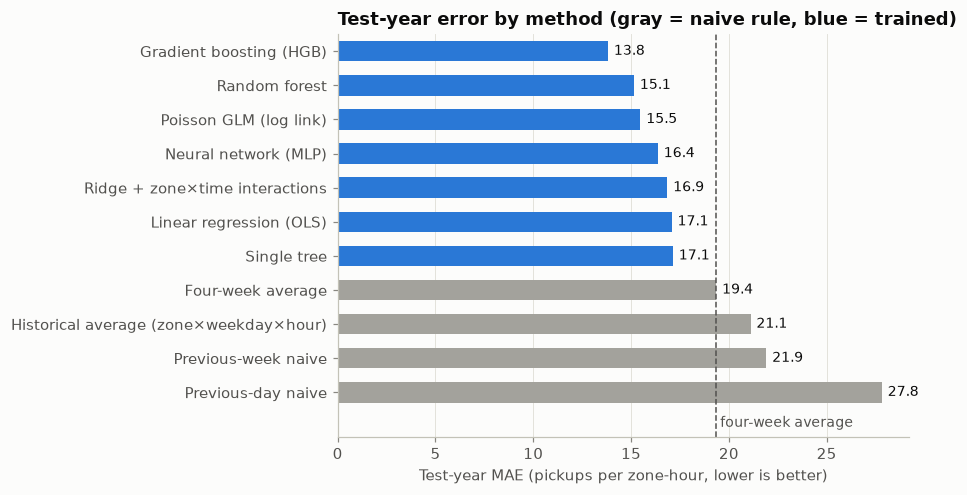

In [14]:
plot_tab = test_table.drop(index=WEATHER_LABEL).sort_values("MAE", ascending=True)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
colors = [BASE_GRAY if TIER[k] == "naive benchmark" else BLUE for k in plot_tab.index]
ax.barh(plot_tab.index[::-1], plot_tab["MAE"][::-1], color=colors[::-1], height=0.6)
base = test_table.loc["Four-week average", "MAE"]
ax.axvline(base, color=INK2, lw=1, ls="--")
ax.text(base, -0.9, " four-week average", color=INK2, fontsize=9, va="center")
ax.set_ylim(-1.3, len(plot_tab) - 0.5)
for i, (k, v) in enumerate(plot_tab["MAE"][::-1].items()):
    ax.text(v + 0.3, i, f"{v:.1f}", va="center", color=INK, fontsize=9)
ax.set_xlabel("Test-year MAE (pickups per zone-hour, lower is better)")
ax.set_title("Test-year error by method (gray = naive rule, blue = trained)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Headline result (test year, never touched during model selection; all models use the same features)**
- **Gradient boosting: MAE 13.82, WAPE 14.1%**, i.e. **28.6% smaller errors than the four-week average** (19.35),
  **37% smaller than the previous-week rule** and **50% smaller than the previous-day rule**. That is 5.5 fewer
  mis-forecast pickups per zone-hour.
- **Random forest (+21.7%) and Poisson GLM (+20.0%)** are the runners-up. The GLM gets most of the gain while staying
  fully interpretable and training in seconds.
- **Ridge (+12.9%), OLS (+11.8%) and the single tree (+11.4%)** give modest gains.
- **The neural network is the one model that didn't hold up from CV to test:** 2nd in CV (14.05) but 4th on test
  (16.37, +15.4%), while gradient boosting held steady (13.84 → 13.82). The per-month table in section 8 shows why: from
  March to November the network is close to gradient boosting (it even wins September), but in **January and
  February its error nearly doubles** (27.2 and 25.8 vs about 15), as bad as the four-week average. CV only validates
  March–August, so it never saw winter. The earlier CPU network (one 64-unit layer) scored 15.29 on test, so the
  network's result also swings by a full point with its set-up. Gradient boosting is the robust choice.
- Every other model keeps its CV rank on test, and gains on test are *larger* than in CV. The test year includes
  Thanksgiving, Christmas–New Year and two winter storms, which break the four-week average far more than the
  models (section 8).
- **Weather check:** the same gradient-boosting model *without* weather scores **13.64**, slightly *better* than with
  it. Weather adds nothing on test, so the "perfect weather forecast" caveat doesn't inflate the headline. A
  dispatcher could run this model without a weather feed and lose nothing.
- The zone × weekday × hour **historical average is worse than the four-week average** as a forecast (it misses the
  2025–26 level), yet it is the most useful model *input* (section 8): the model takes each zone's shape from it
  and the current level from recent lags.
- All trained models **under-forecast by 1–3%**. Operationally that means slightly too few cabs; a bias correction
  fitted on CV residuals is an easy next step.

## 8. Where does the best model gain, and where does it struggle?

All diagnostics below are on the test year, comparing the best model with the four-week-average baseline.

In [15]:
diag = test_f[["zone_id", "zone_name", "borough", "ts_hour", "hr", "dow", "is_holiday", TARGET]].copy()
diag["base"] = test_pred["Four-week average"]
diag["model"] = test_pred[BEST]
diag["err_base"] = (diag.base - diag[TARGET]).abs()
diag["err_model"] = (diag.model - diag[TARGET]).abs()
diag["group"] = np.where(diag.borough == "Manhattan", "Manhattan (47 zones)", "Airports (JFK + LGA)")


def group_report(g):
    y = g[TARGET].sum()
    return pd.Series({"zone-hours": len(g), "mean pickups": g[TARGET].mean(),
                      "baseline MAE": g.err_base.mean(), "model MAE": g.err_model.mean(),
                      "baseline WAPE %": 100 * g.err_base.sum() / y, "model WAPE %": 100 * g.err_model.sum() / y,
                      "gain vs 4-wk (%)": 100 * (1 - g.err_model.sum() / g.err_base.sum()),
                      "model bias %": 100 * (g.model.sum() - y) / y})


print(f"Best model: {BEST}")
display(diag.groupby("group").apply(group_report, include_groups=False))

zone_rep = diag.groupby("zone_name").apply(group_report, include_groups=False).sort_values("gain vs 4-wk (%)")
print("Zones with the smallest and largest gains:")
display(pd.concat([zone_rep.head(5), zone_rep.tail(5)]))
print(f"Model beats the four-week average in {(zone_rep['gain vs 4-wk (%)'] > 0).sum()} of {len(zone_rep)} zones.")

Best model: Gradient boosting (HGB)


,zone-hours,mean pickups,baseline MAE,model MAE,baseline WAPE %,model WAPE %,gain vs 4-wk (%),model bias %
group,,,,,,,,
Airports (JFK + LGA),"17,520.00",176.26,37.86,30.79,21.48,17.47,18.66,1.68
Manhattan (47 zones),"411,720.00",94.51,18.56,13.10,19.64,13.86,29.45,-2.34


Zones with the smallest and largest gains:


,zone-hours,mean pickups,baseline MAE,model MAE,baseline WAPE %,model WAPE %,gain vs 4-wk (%),model bias %
zone_name,,,,,,,,
East Harlem North,"8,760.00",22.76,5.83,5.13,25.61,22.56,11.91,-3.81
Central Harlem,"8,760.00",25.90,6.81,5.79,26.29,22.34,15.05,-4.94
JFK Airport,"8,760.00",216.10,40.44,33.85,18.71,15.66,16.30,1.00
East Harlem South,"8,760.00",42.94,8.78,7.24,20.45,16.87,17.55,-5.52
Clinton West,"8,760.00",38.47,10.16,8.33,26.41,21.66,17.97,-5.25
TriBeCa/Civic Center,"8,760.00",74.08,17.13,11.16,23.12,15.07,34.84,-3.64
Gramercy,"8,760.00",100.59,21.09,13.69,20.96,13.61,35.10,-2.25
Union Sq,"8,760.00",138.44,26.25,16.95,18.96,12.24,35.41,-2.57
Upper East Side South,"8,760.00",238.78,43.41,24.41,18.18,10.22,43.76,-1.87


Model beats the four-week average in 49 of 49 zones.


**Where is demand hardest to forecast?** Map of the best model's test-year **WAPE** by zone (error as a share of the
zone's demand). MAE is not used here because it grows with volume and would simply highlight the busiest zones.

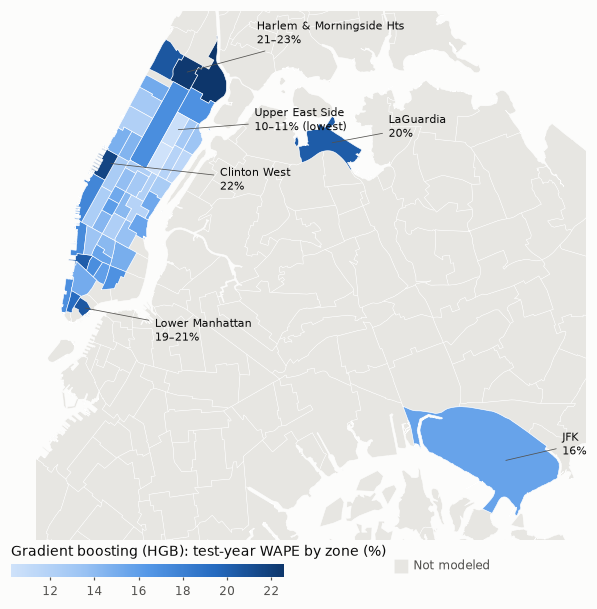

zone  Upper East Side South  Upper East Side North  Lenox Hill East  Lenox Hill West  Murray Hill  Midtown East  Upper West Side South  Union Sq  Midtown North  East Chelsea  Clinton East  Sutton Place/Turtle Bay North  Yorkville West  Upper West Side North  Midtown Center  West Village  Yorkville East  Gramercy  Times Sq/Theatre District  Midtown South  Greenwich Village North  Flatiron  Lincoln Square East  Lincoln Square West  East Village  TriBeCa/Civic Center  Manhattan Valley  Garment District  UN/Turtle Bay South  Kips Bay  Greenwich Village South  JFK Airport  Little Italy/NoLiTa  Penn Station/Madison Sq West  Lower East Side  East Harlem South  Battery Park City  SoHo  Central Park  Meatpacking/West Village West  West Chelsea/Hudson Yards  World Trade Center  Hudson Sq  LaGuardia Airport  Financial District North  Morningside Heights  Clinton West  Central Harlem  East Harlem North
wape                  10.20                  10.60            11.40            11.80        11.8

In [16]:
import geopandas as gpd
from matplotlib.colors import LinearSegmentedColormap

shapes = DATA / "raw" / "taxi_zones.zip"
if shapes.exists():
    zw = diag.groupby("zone_id").apply(lambda g: 100 * g.err_model.sum() / g[TARGET].sum(), include_groups=False)
    zones = gpd.read_file(f"zip://{shapes}!taxi_zones/taxi_zones.shp")
    zones = zones.merge(zw.rename("wape"), left_on="LocationID", right_index=True, how="left")
    on = zones[zones.wape.notna()]
    ramp = LinearSegmentedColormap.from_list("blue", ["#cfe2fa", "#9ec5f4", "#5598e7", "#256abf", "#0d366b"])

    fig, ax = plt.subplots(figsize=(6.2, 5.6))
    zones[zones.wape.isna()].plot(ax=ax, color="#e7e6e2", edgecolor="white", linewidth=0.3)
    on.plot(ax=ax, column="wape", cmap=ramp, edgecolor="white", linewidth=0.4)
    x0, y0, x1, y1 = on.total_bounds
    pad = 0.05 * max(x1 - x0, y1 - y0)
    ax.set_xlim(x0 - pad, x1 + pad)
    ax.set_ylim(y0 - pad, y1 + pad)
    ax.set_axis_off()
    w = on.set_index("zone").wape
    rng = lambda names: f"{w[names].min():.0f}–{w[names].max():.0f}%"
    labels = [  # (anchor zone, text, x offset, y offset) in map feet
        ("Central Harlem", f"Harlem & Morningside Hts\n{rng(['Central Harlem', 'East Harlem North', 'Morningside Heights'])}", 11000, 6000),
        ("Upper East Side North", f"Upper East Side\n{rng(['Upper East Side North', 'Upper East Side South'])} (lowest)", 12000, 1500),
        ("Clinton West", f"Clinton West\n{w['Clinton West']:.0f}%", 17000, -2500),
        ("Financial District North", f"Lower Manhattan\n{rng(['Financial District North', 'World Trade Center', 'Hudson Sq'])}", 11000, -3500),
        ("LaGuardia Airport", f"LaGuardia\n{w['LaGuardia Airport']:.0f}%", 9000, 2500),
        ("JFK Airport", f"JFK\n{w['JFK Airport']:.0f}%", 9000, 2500),
    ]
    for zone_name, text, dx, dy in labels:
        c = on[on.zone == zone_name].geometry.iloc[0].representative_point()
        ax.annotate(text, (c.x, c.y), (c.x + dx, c.y + dy), fontsize=7.5, color=INK, ha="left", va="center",
                    arrowprops=dict(arrowstyle="-", color=INK2, lw=0.5))
    sm = plt.cm.ScalarMappable(cmap=ramp, norm=plt.Normalize(on.wape.min(), on.wape.max()))
    cax = fig.add_axes([0.06, 0.08, 0.4, 0.022])
    cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8, length=2, colors=INK2)
    fig.text(0.06, 0.115, f"{BEST}: test-year WAPE by zone (%)", fontsize=9, color=INK)
    fig.text(0.62, 0.09, "■", color="#e7e6e2", fontsize=12)
    fig.text(0.65, 0.093, "Not modeled", fontsize=8, color=INK2)
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0.14)
    (OUT / "figures").mkdir(exist_ok=True)
    fig.savefig(OUT / "figures" / "zone_wape_map.png", dpi=200, facecolor=SURFACE)
    plt.show()
    print(on.sort_values("wape")[["zone", "wape"]].set_index("zone").round(1).T.to_string())
else:
    print("Zone shapes not found; run build_dataset.py once to download data/raw/taxi_zones.zip.")

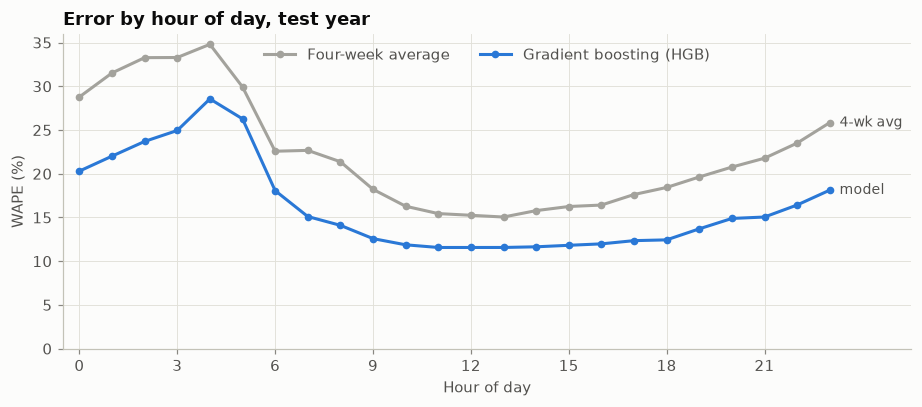

In [17]:
by_hr = diag.groupby("hr")[["err_base", "err_model", TARGET]].sum()
by_hr_wape = 100 * by_hr[["err_base", "err_model"]].div(by_hr[TARGET], axis=0)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(by_hr_wape.index, by_hr_wape.err_base, color=BASE_GRAY, marker="o", ms=4, label="Four-week average")
ax.plot(by_hr_wape.index, by_hr_wape.err_model, color=BLUE, marker="o", ms=4, label=BEST)
ax.text(23.3, by_hr_wape.err_base.iloc[-1], "4-wk avg", color=INK2, va="center", fontsize=9)
ax.text(23.3, by_hr_wape.err_model.iloc[-1], "model", color=INK2, va="center", fontsize=9)
ax.set_xticks(range(0, 24, 3))
ax.set_xlim(-0.5, 25.5)
ax.set_ylim(0, None)
ax.set_xlabel("Hour of day")
ax.set_ylabel("WAPE (%)")
ax.set_title("Error by hour of day, test year")
ax.legend(loc="upper center", ncols=2)
plt.tight_layout()
plt.show()

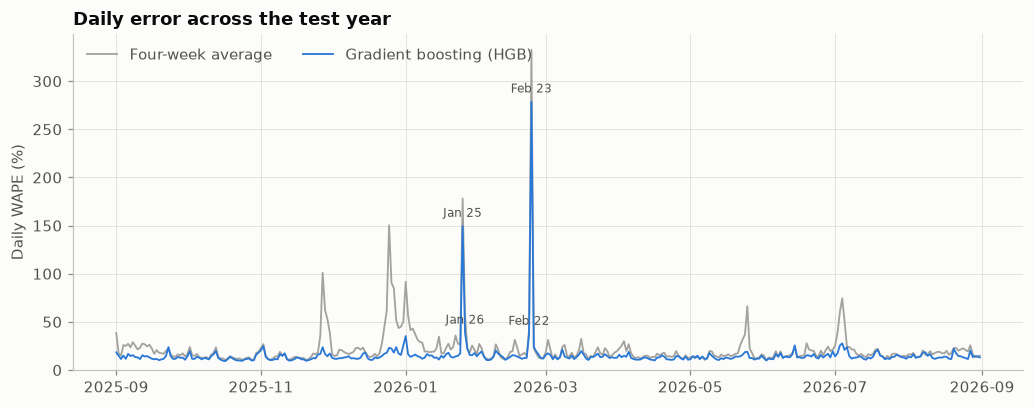

Ten hardest days for the model:


,baseline WAPE %,model WAPE %,gain vs 4-wk (%)
ts_hour,,,
2026-02-23,332.67,278.66,16.23
2026-01-25,178.16,149.53,16.07
2026-01-26,58.00,38.62,33.42
2026-02-22,42.04,37.37,11.11
2026-01-01,91.61,35.31,61.46
2026-07-04,74.53,27.74,62.78
2026-06-14,24.32,25.62,-5.33
2025-12-31,50.27,25.53,49.22
2026-07-03,59.90,25.45,57.51


In [18]:
daily = diag.groupby(diag.ts_hour.dt.date)[["err_base", "err_model", TARGET]].sum()
daily_wape = 100 * daily[["err_base", "err_model"]].div(daily[TARGET], axis=0)
daily_wape.index = pd.to_datetime(daily_wape.index)
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(daily_wape.index, daily_wape.err_base, color=BASE_GRAY, lw=1.2, label="Four-week average")
ax.plot(daily_wape.index, daily_wape.err_model, color=BLUE, lw=1.2, label=BEST)
for d in daily_wape.err_model.nlargest(4).index:
    ax.annotate(d.strftime("%b %d"), (d, daily_wape.err_model[d]), textcoords="offset points", xytext=(0, 6),
                ha="center", fontsize=8, color=INK2)
ax.set_ylim(0, None)
ax.set_ylabel("Daily WAPE (%)")
ax.set_title("Daily error across the test year")
ax.legend(loc="upper left", ncols=2)
plt.tight_layout()
plt.show()

worst = daily_wape.assign(gain_pct=100 * (1 - daily.err_model.values / daily.err_base.values))
worst.columns = ["baseline WAPE %", "model WAPE %", "gain vs 4-wk (%)"]
print("Ten hardest days for the model:")
display(worst.sort_values("model WAPE %", ascending=False).head(10))

**Holiday echo.** Weekly lags (and the four-week average) carry a holiday's low demand into the following weeks. We
check days that fall exactly 7, 14, 21 or 28 days after an office-closed holiday, and the holidays themselves.

In [19]:
hol_days = set(df.loc[df.is_holiday == 1, "ts_hour"].dt.normalize())
day = diag.ts_hour.dt.normalize()
diag["day_type"] = np.select(
    [day.isin(hol_days),
     day.isin({h + pd.Timedelta(days=k) for h in hol_days for k in (7, 14, 21, 28)})],
    ["holiday", "1–4 weeks after a holiday"], "other days")
display(diag.groupby("day_type").apply(group_report, include_groups=False))

,zone-hours,mean pickups,baseline MAE,model MAE,baseline WAPE %,model WAPE %,gain vs 4-wk (%),model bias %
day_type,,,,,,,,
1–4 weeks after a holiday,"41,160.00",93.91,21.32,14.52,22.71,15.46,31.90,-2.12
holiday,"12,936.00",69.87,41.37,14.84,59.21,21.24,64.13,-1.66
other days,"375,144.00",99.24,18.38,13.71,18.52,13.81,25.41,-2.05


**Test error by month.** CV only validated March–August, so this shows how each model holds up in the months CV
never saw (autumn, the holiday season and winter).

In [20]:
month_idx = test_f.ts_hour.dt.to_period("M").astype(str).to_numpy()
monthly = pd.DataFrame({k: pd.Series(np.abs(test_pred[k] - y_test)).groupby(month_idx).mean()
                        for k in ["Four-week average"] + MODEL_NAMES}).T
display(monthly.loc[monthly.mean(axis=1).sort_values().index].round(2))

,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
Gradient boosting (HGB),14.42,13.67,14.35,14.92,15.63,15.00,13.61,12.17,13.07,14.17,12.99,11.95
Random forest,16.99,14.01,16.09,17.99,17.75,15.98,14.30,12.88,14.39,14.95,13.74,12.78
Poisson GLM (log link),16.40,14.09,17.18,20.00,18.30,16.18,14.66,13.06,14.55,15.13,13.89,12.35
Neural network (MLP),14.32,14.14,14.85,19.03,27.24,25.84,14.20,12.74,13.43,15.16,13.74,12.38
Ridge + zone×time interactions,18.75,15.53,18.92,22.33,19.58,16.63,15.56,14.34,15.72,16.08,15.15,13.63
Linear regression (OLS),19.21,15.75,19.14,23.14,19.54,16.56,15.84,14.47,15.93,16.08,15.43,13.78
Single tree,19.09,15.39,18.21,21.72,20.82,17.12,15.88,14.40,16.11,16.60,15.55,14.75
Four-week average,22.68,15.36,20.96,28.82,27.09,17.52,17.05,15.59,17.20,16.75,18.19,14.79


### What drives the predictions?

Permutation importance computed in 26s


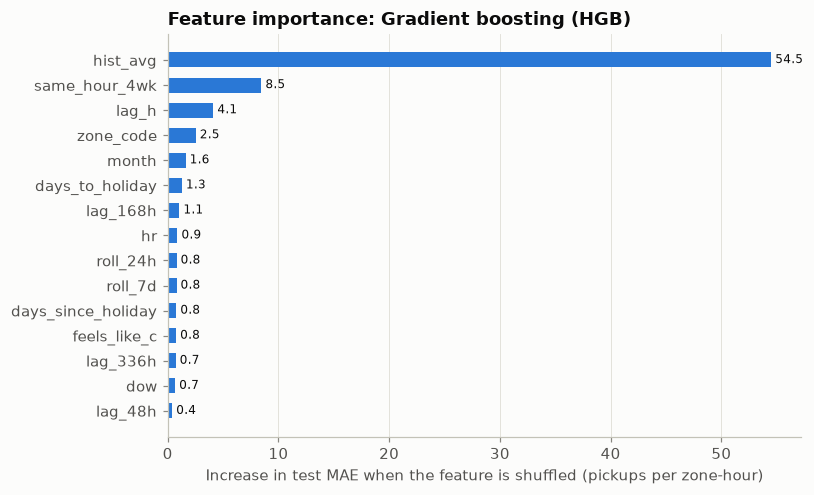

In [21]:
if BEST in LINEAR_MODELS:
    imp_model, imp_cols = fitted[BEST], model_inputs(FEATS)
else:
    imp_model, imp_cols = fitted[BEST], FEATS + ["hist_avg", "trip_missing"]
sample = test_f.sample(30_000 if FAST else 60_000, random_state=SEED)
t = time.time()
pi = permutation_importance(imp_model, sample[imp_cols], sample[TARGET], scoring="neg_mean_absolute_error",
                            n_repeats=3, random_state=SEED, n_jobs=1)
imp = (pd.Series(pi.importances_mean, index=imp_cols).sort_values(ascending=False))
imp = imp[~imp.index.isin(["zone_hr", "zone_dow"]) | (imp > 0)]
print(f"Permutation importance computed in {time.time() - t:.0f}s")

top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
for i, v in enumerate(top.values):
    ax.text(v, i, f" {v:.1f}", va="center", fontsize=8, color=INK)
ax.set_xlabel("Increase in test MAE when the feature is shuffled (pickups per zone-hour)")
ax.set_title(f"Feature importance: {BEST}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Poisson GLM rate ratios.** Because the GLM has a log link, `exp(coefficient)` is the multiplicative effect on expected
pickups. Numeric inputs are standardized, so the ratio is per one standard deviation (for log-lags: per one SD of
log-demand); for one-hot categories it is relative to the average category.

In [22]:
glm = fitted["Poisson GLM (log link)"]
ct, reg = glm[0], glm[-1]
coef = pd.Series(reg.coef_, index=ct.get_feature_names_out())
coef.index = coef.index.str.replace(r"^(cat|log|num)__", "", regex=True)
num_rr = np.exp(coef[~coef.index.str.match(r"(zone_code|hr|dow|month)_")]).sort_values()
print("Rate ratio per 1 SD of each numeric input (1.00 = no effect):")
display(num_rr.to_frame("rate ratio").T)

hr_rr = np.exp(coef[coef.index.str.match(r"hr_")])
hr_rr.index = hr_rr.index.str.replace("hr_", "").astype(int)
dow_rr = np.exp(coef[coef.index.str.match(r"dow_")])
dow_rr.index = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
print("Hour-of-day and weekday multipliers *after* conditioning on the demand lags:")
display(pd.concat([hr_rr.rename("rate ratio").to_frame().T.round(2)]))
display(dow_rr.rename("rate ratio").to_frame().T.round(2))

Rate ratio per 1 SD of each numeric input (1.00 = no effect):


,temp_c,lag_48h,is_holiday_season,trip_missing,is_holiday,duration_lag_h,alert_winter,alert_flood,cloud_cover_pct,snow_depth_m,fare_lag_h,alert_wind,alert_cold,likely_snow,lag_336h,precip_mm,is_precip,alert_heat,wind_kmh,days_since_holiday,days_to_holiday,roll_24h,lag_168h,feels_like_c,lag_h,roll_7d,same_hour_4wk,hist_avg
rate ratio,0.94,0.97,0.97,0.98,0.99,0.99,0.99,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.01,1.01,1.01,1.02,1.04,1.05,1.06,1.07,1.20,1.28,1.44,2.13


Hour-of-day and weekday multipliers *after* conditioning on the demand lags:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
rate ratio,0.99,1.00,1.00,1.00,0.99,0.98,0.99,0.99,0.98,0.98,0.98,0.98,0.97,0.97,0.97,0.97,0.97,0.97,0.97,0.97,0.97,0.97,0.97,0.98


,Sun,Mon,Tue,Wed,Thu,Fri,Sat
rate ratio,0.91,0.96,0.95,0.93,0.93,0.92,0.92


**What the diagnostics say**
- **Wins everywhere:** gradient boosting beats the four-week average in **all 49 zones**. Gains are largest in busy
  Manhattan zones (Upper East Side North/South −44 to −45%, Union Sq −35%) and smallest in low-volume Harlem zones
  (−12 to −15%) and **JFK (−16%)**. Airport demand follows flight schedules, which are not in the data, so that is
  the obvious feature to add.
- **Hour of day:** relative error is highest overnight (0–5 am, small counts) and lowest from 10 am to 4 pm. The model
  improves on the baseline at every hour.
- **Holidays are where the model earns its keep:** on office-closed holidays the four-week average's WAPE is 59%; the
  model's is 21% (**64% gain**). The "holiday echo" (weeks after a holiday, when lags drag the dip forward) is also
  largely fixed (32% gain vs 25% on ordinary days).
- **Failure mode: winter storms, even with weather as an input.** The worst days are 25–26 Jan and 22–23 Feb 2026.
  Both had an NWS winter-storm warning issued more than 24 h ahead (`alert_winter = 3`) and observed snowfall in the
  weather columns, and demand fell to 23–40% of normal (e.g. 19K pickups on 23 Feb vs ~84K expected). The model has
  both signals but has seen only a handful of storm days in training, so it under-reacts. A rule-based storm
  multiplier (the dataset summary notes warning hours ran at ~42% of normal) is a cheap fix.
- **Drivers:** `hist_avg` (each zone's typical weekday × hour shape) dominates, then the four-week average (recent
  level) and yesterday's same hour. Only one weather column, `feels_like_c`, makes the top 15 (12th, +0.8 MAE when
  shuffled), and it partly stands in for season, which `month` also carries.
- **GLM rate ratios tell the same story:** the demand lags carry almost everything (hist_avg ×2.1 per SD, 4-week
  average ×1.44, yesterday ×1.20). Weather effects are small; `temp_c` (×0.94) and `feels_like_c` (×1.07) nearly
  cancel because the two are almost collinear, so don't read them separately. Hour-of-day multipliers are flat
  (0.97–1.00) once lags are in.

## 9. Does it matter? The dollar cost of forecast errors

Accuracy only matters if it changes money. We price every forecast error across **all yellow-cab rides in the 49
zones** (≈ 115,000 a day, served by ~9,800 active taxis), as if dispatchers sent cabs where the day-ahead forecast says
riders will be. Each zone-hour of the test year can go wrong in two ways:

- **Forecast too low → missed rides.** Riders appear but no cab was sent; each one is a lost fare.
  *Example: actual 50, forecast 45 → 5 missed rides × ~\$20 = \$100.*
- **Forecast too high → idle cabs.** Cabs are sent for riders who never appear. Extra forecast rides are turned into
  idle cab-hours (one cab serves ~2.5 rides an hour) and priced at the cost of an idle hour.
  *Example: actual 50, forecast 55 → 5 extra rides ÷ 2.5 = 2 idle cab-hours × ~\$18.70 = \$37.40.*

**Total cost = missed-ride cost + idle-cab cost**, summed over every zone and hour of the year. **Savings** = the
benchmark's total cost − the model's.#
| Assumption | Value | Source |
|---|---|---|
| Rides covered | all yellow-cab pickups in the 49 zones (~9,800 active taxis citywide) | 9,768 active taxis in Dec 2024: [TLC testimony, 10 Feb 2025](https://www.nyc.gov/assets/tlc/downloads/pdf/testimony_2_10_25.pdf) |
| Value of a missed ride | fare kept by the driver, per zone × hour: TLC `total_amount` minus \$4.75 taxes/surcharges (\$6.75 at airports) | [TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page), [TLC taxi fare page](https://www.nyc.gov/site/tlc/passengers/taxi-fare.page) |
| Cost of an idle cab-hour | \$17.00 driver time (NYC minimum wage 2026) + 24¢/mile fuel and maintenance × 7 mph ≈ **\$18.70** | [NYC Business: wage regulations](https://ar.nyc-business.nyc.gov/nycbusiness/description/wage-regulations-in-new-york-state); [AAA Your Driving Costs 2025](https://newsroom.aaa.com/wp-content/uploads/2025/09/UPDATE-AAA-Fact-Sheet-Your-Driving-Cost-9.2025-1.pdf); Manhattan core speeds < 7 mph ([Streetsblog, Jan 2025](https://nyc.streetsblog.org/2025/01/13/its-working-initial-data-show-congestion-pricing-has-stemmed-the-tide-of-years-of-increasing-traffic)) |
| Rides per cab-hour | 2.5 | ≈ \$60/hr median gross pay for full-time yellow drivers ÷ ~\$22 per ride ([TLC testimony, 17 Mar 2026](https://www.nyc.gov/assets/tlc/downloads/pdf/testimony_preliminary_budget_3_17_26.pdf)) |

Why these two prices: the lease and the vehicle are paid whether a cab is busy or not, so an idle hour loses only the
driver's time and fuel. A missed ride loses the fare. Valuing idle time at the driver's \$60/hr gross pay would
double-count, because that pay *is* the fares already counted on the missed-ride side.

In [23]:
FLEET_SHARE = 1.0                       # 1.0 = all yellow-cab pickups in the 49 zones
ACTIVE_TAXIS = 9_768                    # TLC, active taxis Dec 2024
RIDES_PER_CAB_HOUR = 2.5
DRIVER_WAGE = 17.00                     # $/hr, NYC minimum wage 2026
VEHICLE_COST_PER_MILE = 0.1300 + 0.1104  # AAA 2025: fuel + maintenance/repair/tires
CRUISE_MPH = 7.0
IDLE_COST_PER_HOUR = DRIVER_WAGE + VEHICLE_COST_PER_MILE * CRUISE_MPH
PASS_THROUGH = {"Manhattan": 0.50 + 1.00 + 2.50 + 0.75,           # MTA tax, improvement, congestion, CBD toll
                "Queens": 0.50 + 1.00 + 2.50 + 0.75 + 2.00}       # + airport access fee (JFK / LGA pickups)

# Value of a ride: fare_lag_h is the zone's average total_amount 24 h earlier, so weighting it by lag_h (that hour's
# pickups) over the test year gives the zone x hour-of-day average total_amount per trip.
zt = test_f[["zone_id", "zone_name", "borough", "ts_hour", "hr", "fare_lag_h", "lag_h"]].copy()
w = zt.dropna(subset=["fare_lag_h"]).assign(x=lambda g: g.fare_lag_h * g.lag_h)
per_trip = w.groupby(["zone_id", "hr"])[["x", "lag_h"]].sum()
zt = zt.join((per_trip.x / per_trip.lag_h.replace(0, np.nan)).rename("total_per_trip"), on=["zone_id", "hr"])
zt["total_per_trip"] = zt.total_per_trip.fillna(zt.groupby("zone_id").total_per_trip.transform("mean"))
rev = (zt.total_per_trip - zt.borough.map(PASS_THROUGH)).to_numpy()
DAYS = zt.ts_hour.dt.normalize().nunique()
manh = (zt.borough == "Manhattan").to_numpy()

chk = pd.Series({
    "market pickups / day (49 zones)": y_test.sum() / DAYS,
    "market total_amount $ / day (49 zones)": (y_test * zt.total_per_trip).sum() / DAYS,
    "value of a missed ride, Manhattan avg $": np.average(rev[manh], weights=y_test[manh]),
    "value of a missed ride, airports avg $": np.average(rev[~manh], weights=y_test[~manh]),
    "cost of an idle cab-hour $": IDLE_COST_PER_HOUR,
    "idle cost per extra forecast ride $": IDLE_COST_PER_HOUR / RIDES_PER_CAB_HOUR,
})
print("Inputs and sanity checks (TLC reports ~$3M/day citywide yellow-cab farebox revenue):")
display(chk.round(2).to_frame("value"))


def forecast_cost(pred, share=FLEET_SHARE, idle_cost=IDLE_COST_PER_HOUR, rides_per_hour=RIDES_PER_CAB_HOUR):
    """Annual cost of forecast errors for the fleet: missed fares (under-forecast) + idle cab-hours (over-forecast)."""
    f = np.clip(np.asarray(pred, float), 0, None)
    missed = share * np.clip(y_test - f, 0, None)           # fleet rides with no cab sent
    extra = share * np.clip(f - y_test, 0, None)            # fleet rides forecast that never came
    yr = 365 / DAYS
    return {"missed rides / day": missed.sum() / DAYS,
            "idle cab-hours / day": extra.sum() / rides_per_hour / DAYS,
            "Missed-ride cost $/yr": (missed * rev).sum() * yr,
            "Idle-cab cost $/yr": extra.sum() / rides_per_hour * idle_cost * yr}


cost = pd.DataFrame({k: forecast_cost(test_pred[k]) for k in test_table.index}).T
cost["Total cost $/yr"] = cost["Missed-ride cost $/yr"] + cost["Idle-cab cost $/yr"]
for bench, suffix in NAIVE.items():
    cost[f"$ saved {suffix} /yr"] = cost.loc[bench, "Total cost $/yr"] - cost["Total cost $/yr"]
cost.insert(0, "tier", [TIER[k] for k in cost.index])
print(f"Cost of forecast errors, all yellow-cab rides in the 49 zones, test year "
      f"(idle cab-hour ${IDLE_COST_PER_HOUR:.2f}, {RIDES_PER_CAB_HOUR} rides per cab-hour):")
display(cost.round(1))

Inputs and sanity checks (TLC reports ~$3M/day citywide yellow-cab farebox revenue):


,value
market pickups / day (49 zones),"115,065.30"
market total_amount $ / day (49 zones),"3,298,885.89"
"value of a missed ride, Manhattan avg $",20.41
"value of a missed ride, airports avg $",66.20
cost of an idle cab-hour $,18.68
idle cost per extra forecast ride $,7.47


Cost of forecast errors, all yellow-cab rides in the 49 zones, test year (idle cab-hour $18.68, 2.5 rides per cab-hour):


,tier,missed rides / day,idle cab-hours / day,Missed-ride cost $/yr,Idle-cab cost $/yr,Total cost $/yr,$ saved vs prev-day /yr,$ saved vs prev-week /yr,$ saved vs 4-wk avg /yr
Previous-day naive,naive benchmark,"16,348.10","6,547.10","141,115,124.30","44,646,122.80","185,761,247.10",0.00,"-36,908,936.70","-56,594,366.70"
Previous-week naive,naive benchmark,"12,860.50","5,163.10","113,643,938.60","35,208,371.80","148,852,310.40","36,908,936.70",0.00,"-19,685,430.00"
Four-week average,naive benchmark,"11,270.70","4,594.80","97,834,042.40","31,332,837.90","129,166,880.40","56,594,366.70","19,685,430.00",0.00
Historical average (zone×weekday×hour),naive benchmark,"16,333.10","3,394.70","132,650,892.90","23,149,518.30","155,800,411.20","29,960,835.90","-6,948,100.80","-26,633,530.80"
Single tree,trained benchmark,"11,466.20","3,475.10","97,491,450.50","23,697,339.40","121,188,789.90","64,572,457.20","27,663,520.50","7,978,090.40"
Linear regression (OLS),proposed model,"10,756.50","3,729.00","92,780,543.20","25,429,189.30","118,209,732.60","67,551,514.50","30,642,577.90","10,957,147.80"
Ridge + zone×time interactions,proposed model,"10,564.10","3,701.70","91,417,125.20","25,242,978.20","116,660,103.40","69,101,143.70","32,192,207.00","12,506,777.00"
Poisson GLM (log link),proposed model,"10,144.10","3,222.10","88,764,235.90","21,972,055.30","110,736,291.20","75,024,955.90","38,116,019.20","18,430,589.20"
Random forest,proposed model,"10,125.20","3,075.50","86,438,629.40","20,972,625.50","107,411,254.90","78,349,992.20","41,441,055.60","21,755,625.50"
Gradient boosting (HGB),proposed model,"9,303.50","2,779.20","80,391,236.70","18,952,192.50","99,343,429.20","86,417,817.90","49,508,881.20","29,823,451.10"


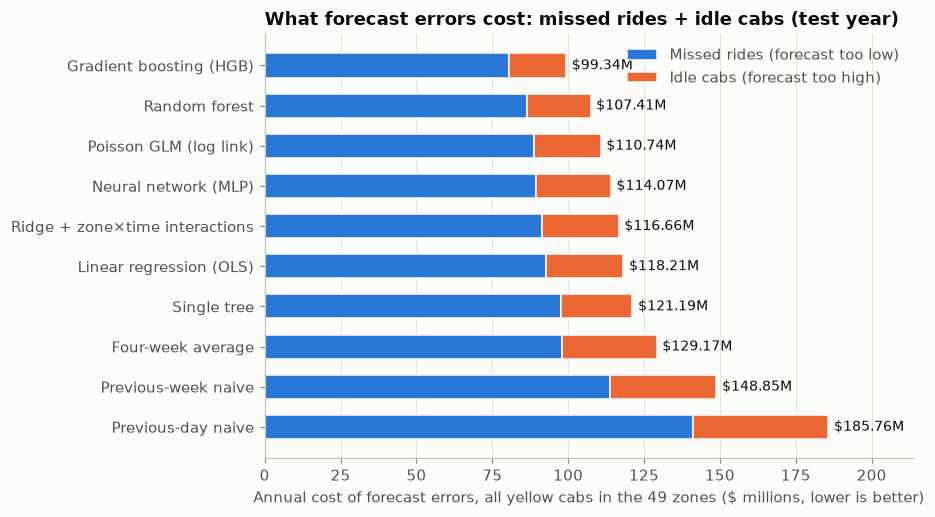

In [24]:
plot_c = cost.drop(index=[WEATHER_LABEL, "Historical average (zone×weekday×hour)"]).sort_values("Total cost $/yr",
                                                                                                ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
miss_m, idle_m = plot_c["Missed-ride cost $/yr"] / 1e6, plot_c["Idle-cab cost $/yr"] / 1e6
ax.barh(plot_c.index, miss_m, color=BLUE, height=0.6, label="Missed rides (forecast too low)",
        edgecolor=SURFACE, linewidth=1)
ax.barh(plot_c.index, idle_m, left=miss_m, color=ORANGE, height=0.6, label="Idle cabs (forecast too high)",
        edgecolor=SURFACE, linewidth=1)
for i, (k, tot) in enumerate((plot_c["Total cost $/yr"] / 1e6).items()):
    ax.text(tot + plot_c['Total cost $/yr'].max() / 1e6 * 0.01, i, f"${tot:.2f}M", va="center", fontsize=9, color=INK)
ax.set_xlim(0, plot_c["Total cost $/yr"].max() / 1e6 * 1.15)
ax.set_xlabel("Annual cost of forecast errors, all yellow cabs in the 49 zones ($ millions, lower is better)")
ax.set_title("What forecast errors cost: missed rides + idle cabs (test year)")
ax.legend(loc="upper right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Sensitivity.** The idle-cab side depends on what an idle hour costs and how many rides a cab serves per hour.
A single fleet would save in proportion to its share of rides.

In [25]:
grid = pd.DataFrame(index=pd.Index([15.0, round(IDLE_COST_PER_HOUR, 2), 30.0], name="idle cost $/cab-hour"),
                    columns=pd.Index([2.0, 2.5, 3.0], name="rides per cab-hour"), dtype=float)
for ic in grid.index:
    for rph in grid.columns:
        tot = lambda k: sum(v for n, v in forecast_cost(test_pred[k], idle_cost=ic, rides_per_hour=rph).items()
                            if n.endswith("$/yr"))
        grid.loc[ic, rph] = tot("Four-week average") - tot(BEST)
print(f"{BEST} vs four-week average: $ saved per year, all yellow-cab rides in the 49 zones")
display((grid / 1e6).round(2).astype(str).radd("$").add("M"))
share_scale = pd.Series({f"fleet with {sh:.0%} of rides (≈{sh * ACTIVE_TAXIS:,.0f} cabs)":
                         cost.loc[BEST, "$ saved vs 4-wk avg /yr"] * sh / FLEET_SHARE / 1e6 for sh in (0.05, 0.25, 1.0)})
print("Base-case savings for a single fleet, by its share of rides ($M per year):")
display(share_scale.round(2).to_frame("$M / yr"))

Gradient boosting (HGB) vs four-week average: $ saved per year, all yellow-cab rides in the 49 zones


rides per cab-hour,2.00,2.50,3.00
idle cost $/cab-hour,,,
15.00,$29.87M,$27.38M,$25.73M
18.68,$32.92M,$29.82M,$27.76M
30.00,$42.29M,$37.32M,$34.01M


Base-case savings for a single fleet, by its share of rides ($M per year):


,$M / yr
fleet with 5% of rides (≈488 cabs),1.49
"fleet with 25% of rides (≈2,442 cabs)",7.46
"fleet with 100% of rides (≈9,768 cabs)",29.82


### Final table: accuracy and dollars

In [26]:
DOLLAR_COLS = ["Missed-ride cost $/yr", "Idle-cab cost $/yr", "Total cost $/yr", "$ saved vs 4-wk avg /yr"]
final = final.join(cost[DOLLAR_COLS])
final.to_csv(OUT / "model_comparison.csv", float_format="%.3f")
show = final[["tier", "CV MAE", "Test MAE", "Test WAPE %", "Gain vs prev-day (%)", "Gain vs prev-week (%)",
              "Gain vs 4-wk avg (%)"] + DOLLAR_COLS].copy()
for c in DOLLAR_COLS:
    show[c] = show[c].map(lambda v: f"{'+' if c.startswith('$ saved') and v > 0 else ''}"
                                    f"{'−' if v < 0 else ''}${abs(v) / 1e6:,.2f}M")
print(f"Test year. Dollar columns: annual cost of forecast errors across all yellow-cab rides in the 49 zones. "
      f"Saved to {OUT / 'model_comparison.csv'}")
display(show.round(2))

Test year. Dollar columns: annual cost of forecast errors across all yellow-cab rides in the 49 zones. Saved to /home/leeanddrew/harvard/ai-edge/ai-edge-nyc-taxi-demand/results/model_comparison.csv


,tier,CV MAE,Test MAE,Test WAPE %,Gain vs prev-day (%),Gain vs prev-week (%),Gain vs 4-wk avg (%),Missed-ride cost $/yr,Idle-cab cost $/yr,Total cost $/yr,$ saved vs 4-wk avg /yr
Previous-day naive,naive benchmark,28.40,27.82,28.43,0.00,-26.96,-43.76,$141.12M,$44.65M,$185.76M,−$56.59M
Previous-week naive,naive benchmark,20.45,21.91,22.39,21.24,0.00,-13.23,$113.64M,$35.21M,$148.85M,−$19.69M
Four-week average,naive benchmark,17.41,19.35,19.78,30.44,11.68,0.00,$97.83M,$31.33M,$129.17M,$0.00M
Historical average (zone×weekday×hour),naive benchmark,20.70,21.11,21.57,24.13,3.68,-9.06,$132.65M,$23.15M,$155.80M,−$26.63M
Single tree,trained benchmark,16.86,17.14,17.52,38.40,21.79,11.44,$97.49M,$23.70M,$121.19M,+$7.98M
Linear regression (OLS),proposed model,16.55,17.07,17.45,38.63,22.08,11.77,$92.78M,$25.43M,$118.21M,+$10.96M
Ridge + zone×time interactions,proposed model,16.35,16.85,17.22,39.42,23.09,12.92,$91.42M,$25.24M,$116.66M,+$12.51M
Poisson GLM (log link),proposed model,15.10,15.48,15.82,44.37,29.37,20.03,$88.76M,$21.97M,$110.74M,+$18.43M
Random forest,proposed model,15.10,15.15,15.48,45.55,30.87,21.72,$86.44M,$20.97M,$107.41M,+$21.76M
Gradient boosting (HGB),proposed model,13.84,13.82,14.12,50.33,36.93,28.59,$80.39M,$18.95M,$99.34M,+$29.82M


**Reading the dollar results** (all yellow-cab rides in the 49 zones, test year)
- **Gradient boosting cuts the cost of forecast errors from \$129.2M to \$99.3M a year: \$29.8M saved** vs the
  four-week average (−23%), about 2.5% of the ≈ \$1.2B a year in taxi revenue in these zones, or ≈ \$3,000 per active
  taxi. Against the simpler rules it saves \$49.5M (previous week) and \$86.4M (previous day).
- **Both sides improve:** missed rides fall from ~11,300 to ~9,300 a day (−\$17.4M a year) and idle cab-hours from
  ~4,600 to ~2,800 a day (−\$12.4M a year).
- **Every trained model saves money and the ranking follows accuracy:** random forest \$21.8M, Poisson GLM \$18.4M
  (about 60% of gradient boosting's savings), neural network \$15.1M, Ridge \$12.5M, OLS \$11.0M, single tree \$8.0M.
  The zone × weekday × hour average *costs* \$26.6M more than the baseline because it misses the 2025–26 demand level.
- **Missed rides are the expensive mistake:** a missed ride loses ~\$20 in fares, while each extra forecast ride wastes
  only ~\$7.50 of idle time (\$18.68/hr ÷ 2.5 rides). Missed rides make up about 80% of every method's cost. Since all
  trained models under-forecast slightly (1–3%), nudging forecasts upward is a cheap way to save more.
- **Sensitivity:** \$25.7M–\$42.3M a year across idle costs of \$15–30/hr and 2–3 rides per cab-hour. A single fleet
  saves in proportion to its share of rides (≈ \$1.5M a year for a 500-cab fleet).
- **Caveats:** TLC data records completed trips only, so true demand in under-served hours is understated. The
  calculation assumes cabs can be sent to each zone as the forecast says, and that their presence doesn't change
  demand. These are simulated savings to be confirmed in a pilot, not observed revenue.

## 10. Summary

All models use the identical feature set: every planned column in `dataset_summary.pdf` (including weather and
NWS alerts) + `hist_avg`.

| | Test MAE | Gain vs 4-wk avg | \$ saved / yr vs 4-wk avg (all rides) | Take-away |
|---|---:|---:|---:|---|
| Four-week average (best naive rule) | 19.35 | — | — | The bar to beat (errors cost \$129.2M a year) |
| **Gradient boosting (HGB, Poisson loss)** | **13.82** | **+28.6%** | **+\$29.8M** | Best model; wins in every zone, month and hour, and stable from CV to test |
| Random forest | 15.15 | +21.7% | +\$21.8M | Strong but slower, and worse than HGB |
| Poisson GLM (log link) | 15.48 | +20.0% | +\$18.4M | Best *interpretable* model; ~60% of HGB's savings |
| Neural network (PyTorch, 256 → 128 → 64) | 16.37 | +15.4% | +\$15.1M | 2nd in CV, but collapses in Jan–Feb, months CV never tested |
| Ridge + interactions / OLS / single tree | 16.9–17.1 | +11–13% | +\$8.0–12.5M | Linear-in-counts structure leaves accuracy and money on the table |

1. **Day-ahead ML forecasts beat dispatcher rules:** about 29% fewer mis-forecast pickups than the best naive rule,
   consistently across CV months and on a full unseen year.
2. **In dollars:** across all yellow-cab rides in these zones, gradient boosting cuts the cost of forecast errors
   (missed fares + idle cabs) by ≈ \$29.8M a year vs the best naive rule, and by ≈ \$86M vs "same hour yesterday".
   Missed rides are the costly side, so slight over-forecasting is cheaper than under-forecasting.
3. **More complexity is not automatically better:** the neural network didn't beat gradient boosting and was the
   least robust out of season.
4. **Weather does not matter for this forecast:** the best model without weather is just as accurate (13.64).
5. **Recommendation:** forecast with gradient boosting, keep the Poisson GLM as the explainable cross-check, add a
   winter-storm override and a small upward bias correction, and validate the savings in a pilot.
6. **Next steps:** add winter months to the CV window; add flight schedules for the airports; tune the bias correction
   on CV.

In [27]:
print(f"Total notebook runtime: {(time.time() - T0) / 60:.1f} min")

Total notebook runtime: 0.5 min
